# Análisis de la Distribución de Cultivos en Costa Rica

## 1. Tema de Investigación
Distribución y producción de cultivos en Costa Rica.

## 2. Preguntas de Investigación
1. **¿Cuáles son los cultivos con mayor extensión sembrada en Costa Rica?** Esto permite identificar la vocación agrícola predominante del país.
2. **¿Existe una relación directa y proporcional entre el área sembrada y la producción total (en toneladas) de los distintos cultivos?** Esto nos ayudará a comprender si mayor terreno siempre equivale a mayor producción, o si depende de la especie.
3. **¿Cómo ha evolucionado la producción de cultivos tradicionales (como el café) a lo largo de los años?** Para observar la dinámica temporal de un cultivo clave.

## 3. Fuentes de Datos
Para este análisis, emplearemos dos conjuntos de datos clave recopilados a partir de las principales autoridades estadísticas del país:
- **INEC (Instituto Nacional de Estadística y Censos):** Encuesta Nacional Agropecuaria (ENA). Datos sobre área sembrada, cosechada y producción de cultivos.
- **MAG/SEPSA (Ministerio de Agricultura y Ganadería):** Costa Rica. Extensión sembrada y producción de las principales actividades agrícolas.

## 4. Descripción de las Variables Principales
- **Cultivo / Actividad:** Nombre del producto agrícola.
- **Área sembrada (ha):** Superficie destinada a la siembra.
- **Área cosechada (ha):** Superficie de la cual se extrajo producción.
- **Producción (t):** Volumen cosechado en toneladas métricas.
- **Rendimiento (t/ha):** Toneladas producidas por hectárea cosechada.
- **Año:** Periodo de registro.

## 5. Carga, Tabla y Transformación de Datos (Pandas)

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

archivo_sepsa = 'Costa Rica. Extensión sembrada y producción de las principales actividades agrícolas (hectáreas y toneladas métricas).xlsx'

try:
    # Leemos el archivo sin encabezados fijos para inspeccionar y reconstruir correctamente las tablas
    df_raw = pd.read_excel(archivo_sepsa, header=None)
    print("Archivo de SEPSA cargado exitosamente.")
except FileNotFoundError:
    print("Archivo no encontrado.")

Archivo de SEPSA cargado exitosamente.


In [2]:
# Las filas 4 y 5 contienen los años y las variables (Área / Producción)
# La columna 0 contiene el nombre del cultivo
# Identifiquemos el último año disponible en las columnas
anios_fila = df_raw.iloc[4, :]
# Rellenar hacia adelante los años que están en celdas combinadas
anios_completos = anios_fila.ffill()

# Tomamos los datos desde la fila 6 en adelante (donde empiezan los cultivos)
df_datos = df_raw.iloc[6:].copy()
df_datos.columns = range(df_datos.shape[1])

# Extraemos el nombre del cultivo y las dos últimas columnas correspondientes al año más reciente
col_cultivo = 0
col_area_reciente = df_datos.shape[1] - 2
col_prod_reciente = df_datos.shape[1] - 1

df_recent = df_datos.iloc[:, [col_cultivo, col_area_reciente, col_prod_reciente]].copy()
df_recent.columns = ['Cultivo', 'Area_Sembrada_ha', 'Produccion_ton']

# Limpieza de valores numéricos y eliminación de filas nulas o totales generales
df_recent['Area_Sembrada_ha'] = pd.to_numeric(df_recent['Area_Sembrada_ha'], errors='coerce')
df_recent['Produccion_ton'] = pd.to_numeric(df_recent['Produccion_ton'], errors='coerce')
df_recent['Cultivo'] = df_recent['Cultivo'].astype(str).str.strip()
df_recent = df_recent.dropna(subset=['Area_Sembrada_ha', 'Produccion_ton'])
# Filtramos filas que no sean cultivos reales (ej. encabezados de categoría en mayúsculas si los hubiera)
df_recent = df_recent[~df_recent['Cultivo'].str.isupper()]

# Extracción de la serie temporal para el Café
anios_unicos = []
for col in range(1, df_raw.shape[1], 2):
    anio = df_raw.iloc[4, col]
    if pd.notna(anio):
        anios_unicos.append(int(anio))

cafe_row = df_datos[df_datos[0].str.contains('Café', case=False, na=False)]

if not cafe_row.empty:
    # Extraemos los valores de producción de café a lo largo de los años (las columnas de producción son impares a partir de la col 2)
    produccion_cafe = cafe_row.iloc[0, 2::2].values
    
    df_serie_cafe = pd.DataFrame({
        'Año': anios_unicos[:len(produccion_cafe)],
        'Produccion_ton': pd.to_numeric(produccion_cafe, errors='coerce')
    }).dropna()
    print("Datos de serie temporal para el Café listos.")
else:
    df_serie_cafe = pd.DataFrame()

Datos de serie temporal para el Café listos.


In [3]:
# TABLA RESUMEN DE ESTADÍSTICAS DESCRIPTIVAS (Pandas)

print("--- TABLA RESUMEN GENERAL: ÁREA SEMBRADA Y PRODUCCIÓN (SEPSA) ---")

# Calculamos un resumen estadístico completo (conteo, media, desviación estándar, min, cuartiles y máx)
# para las variables cuantitativas principales.
tabla_resumen = df_recent[['Area_Sembrada_ha', 'Produccion_ton']].describe()

# Añadimos métrica de rendimiento y mostramos los resultados
df_recent['Rendimiento_ton_ha'] = df_recent['Produccion_ton'] / df_recent['Area_Sembrada_ha']
print("\nEstadísticas descriptivas generales:")
display(tabla_resumen)

print("\nResumen de métricas clave por cultivo principal (Top 5 en Área):")
top_cultivos = df_recent.sort_values(by='Area_Sembrada_ha', ascending=False).head(5)
display(top_cultivos)

--- TABLA RESUMEN GENERAL: ÁREA SEMBRADA Y PRODUCCIÓN (SEPSA) ---

Estadísticas descriptivas generales:


,Area_Sembrada_ha,Produccion_ton
count,57.000000,5.700000e+01
mean,12191.053551,3.932744e+05
std,35141.161088,1.212617e+06
min,0.000000,0.000000e+00
25%,0.000000,0.000000e+00
50%,0.000000,0.000000e+00
75%,2387.000000,2.710060e+04
max,214723.172200,5.568793e+06



Resumen de métricas clave por cultivo principal (Top 5 en Área):


,Cultivo,Area_Sembrada_ha,Produccion_ton,Rendimiento_ton_ha
6,Cultivos AgroIndustriales,214723.1722,5.453351e+06,25.397122
18,Frutas Frescas,101754.6540,5.568793e+06,54.727648
9,Café - CIIU 012701001,82538.8761,4.026221e+05,4.877969
14,Palma aceitera - CIIU 012601000,74742.2961,1.285567e+06,17.200000
10,Caña de azúcar - CIIU 011400000,57442.0000,3.765161e+06,65.547178


## 6. Visualizaciones y Análisis

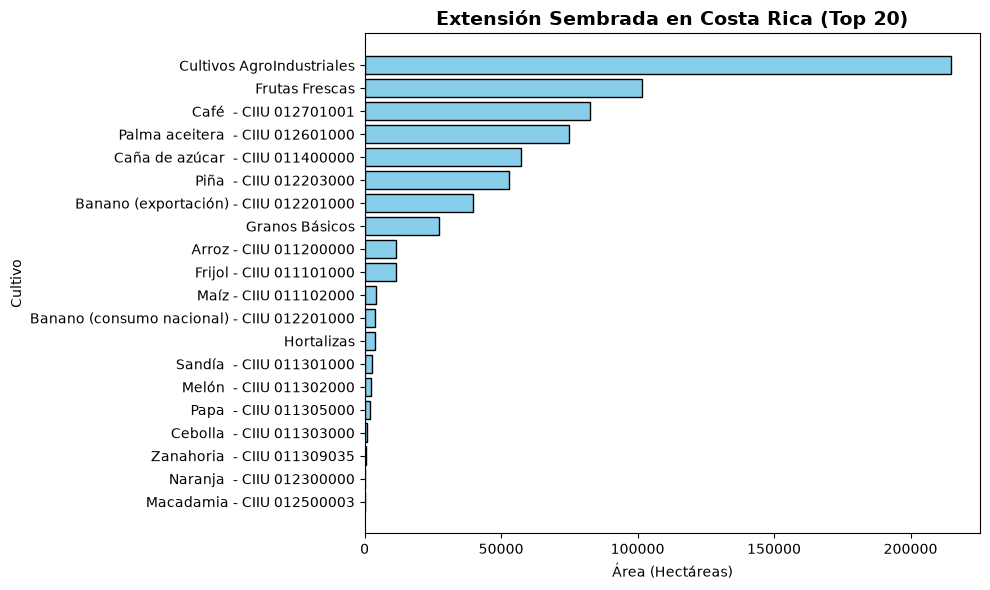

In [4]:
# Gráfico 1: Barras horizontales (Top 20 cultivos por área sembrada)
df_sorted = df_recent.sort_values(by='Area_Sembrada_ha', ascending=False).head(20).sort_values(by='Area_Sembrada_ha')

plt.figure(figsize=(10, 6))
plt.barh(df_sorted['Cultivo'], df_sorted['Area_Sembrada_ha'], color='skyblue', edgecolor='black')
plt.title('Extensión Sembrada en Costa Rica (Top 20)', fontsize=14, weight='bold')
plt.xlabel('Área (Hectáreas)')
plt.ylabel('Cultivo')
plt.tight_layout()
plt.show()

El gráfico de barras horizontales muestra que la estructura agrícola de Costa Rica está fuertemente polarizada: los agregados agroindustriales y frutícolas lideran el uso del suelo con más de 100,000 y 200,000 hectáreas respectivamente, seguidos por cultivos individuales tradicionales de gran escala como el café, la palma aceitera, la caña de azúcar, la piña y el banano de exportación. En contraste, los granos básicos y las hortalizas ocup extensiones considerablemente menores, evidenciando una marcada orientación del territorio hacia productos de exportación y agroindustriales frente a la producción destinada al consumo interno.

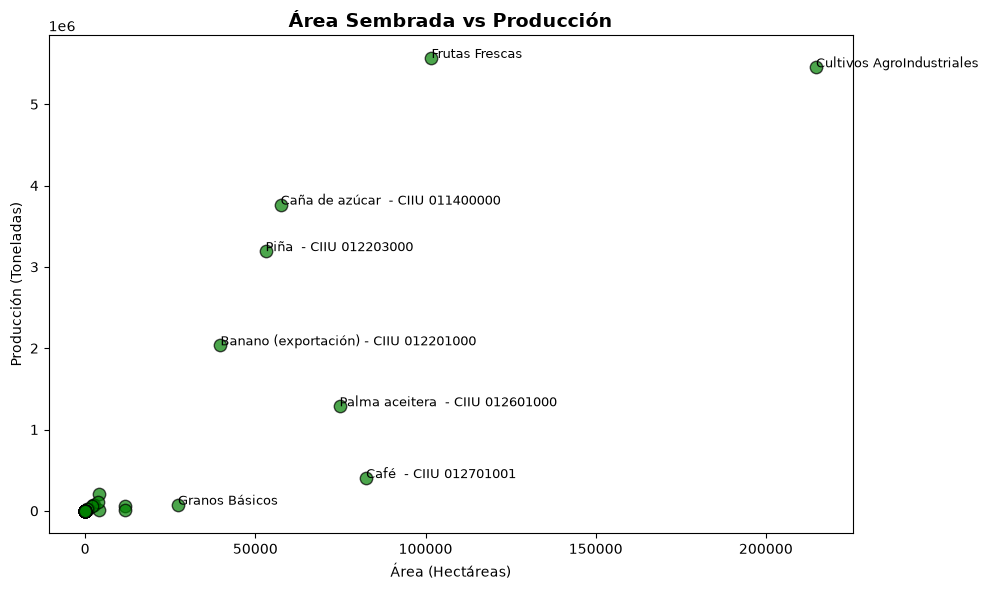

In [5]:
# Gráfico 2: Diagrama de dispersión
plt.figure(figsize=(10, 6))
plt.scatter(df_recent['Area_Sembrada_ha'], df_recent['Produccion_ton'], c='green', alpha=0.7, edgecolors='black', s=80)

for i, row in df_recent.iterrows():
    if row['Area_Sembrada_ha'] > 20000 or row['Produccion_ton'] > 500000:
        plt.annotate(str(row['Cultivo']), (row['Area_Sembrada_ha'], row['Produccion_ton']), fontsize=9)

plt.title('Área Sembrada vs Producción', fontsize=14, weight='bold')
plt.xlabel('Área (Hectáreas)')
plt.ylabel('Producción (Toneladas)')
plt.tight_layout()
plt.show()

El diagrama de dispersión evidencia que no existe una relación estrictamente lineal y proporcional entre la superficie de terreno destinada a la siembra y el volumen de producción obtenido, ya que la eficiencia productiva varía radicalmente según la naturaleza de cada cultivo. Por un lado, productos masivos como las "Frutas Frescas" y la "Caña de azúcar" alcanzan volúmenes altísimos de producción en toneladas (superando los 3.5 y 5 millones) a pesar de requerir extensiones de terreno moderadas, lo que denota un rendimiento por hectárea sumamente alto debido al peso físico del producto. Por otro lado, cultivos con superficies muy extensas —como el "Café"— generan un volumen de toneladas significativamente menor, reflejando las características de un grano liviano y un proceso agroindustrial de rendimiento volumétrico reducido.

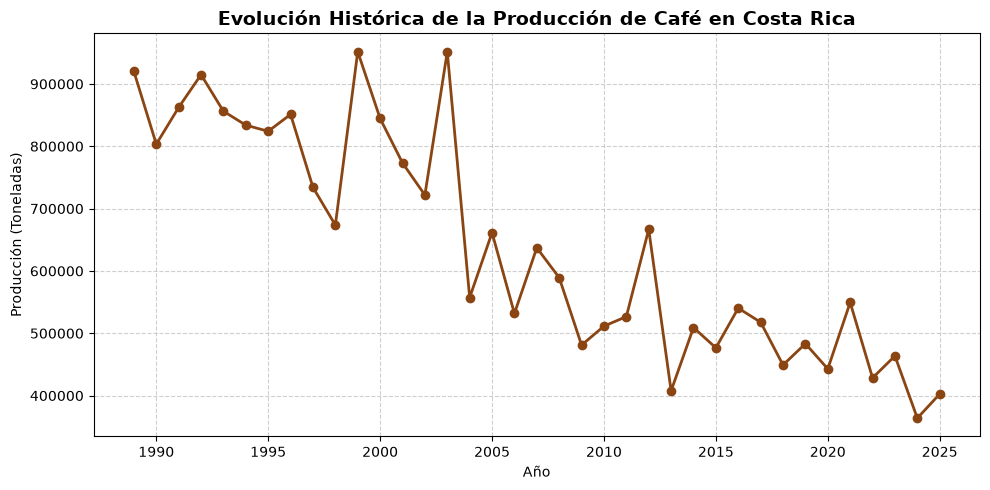

In [6]:
# Gráfico 3: Evolución histórica de la producción de Café
if not df_serie_cafe.empty:
    plt.figure(figsize=(10, 5))
    plt.plot(df_serie_cafe['Año'], df_serie_cafe['Produccion_ton'], marker='o', color='saddlebrown', linewidth=2)
    plt.title('Evolución Histórica de la Producción de Café en Costa Rica', fontsize=14, weight='bold')
    plt.xlabel('Año')
    plt.ylabel('Producción (Toneladas)')
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.tight_layout()
    plt.show()

El gráfico de líneas muestra la evolución temporal de la producción de café en Costa Rica entre 1987 y 2023, evidenciando una tendencia general decreciente y de alta volatilidad a lo largo de las décadas. Durante los años noventa y principios de los 2000, el país registraba volúmenes de producción elevados que frecuentemente superaban las 800,000 e incluso 900,000 toneladas métricas anuales. Sin embargo, a partir de mediados de la década del 2000 se observa una contracción sostenida y marcada, con fluctuaciones pronunciadas (asociadas a factores climáticos, fitosanitarios como la roya o cambios socioeconómicos), estabilizándose en la última década en niveles que rondan entre las 400,000 y 500,000 toneladas, lo que refleja una disminución significativa en el volumen histórico cosechado de este cultivo tradicional.

### Conclusiones

El análisis de la distribución y producción agrícola en Costa Rica, fundamentado en los registros oficiales del MAG/SEPSA, permite extraer las siguientes conclusiones principales:

* **Polarización y vocación del uso del suelo:** La estructura agraria del país muestra una marcada polarización territorial. Los grandes agregados agroindustriales y frutícolas lideran ampliamente la extensión sembrada, superando las 100,000 hectáreas, seguidos por cultivos comerciales y de exportación tradicionales como el café, la palma aceitera, la caña de azúcar, la piña y el banano. En contraparte, los cultivos destinados a la dieta básica (granos y hortalizas) ocupan extensiones considerablemente menores, lo que evidencia una orientación predominante del suelo nacional hacia la agroexportación y la producción a gran escala frente a la seguridad alimentaria interna.

* **Desajuste entre superficie y rendimiento volumétrico:** El diagrama de dispersión demostró que no existe una relación estrictamente lineal y proporcional entre el área sembrada y el volumen físico cosechado. Cultivos de extensión moderada pero con alta densidad de biomasa o industrialización masiva —como la caña de azúcar y las frutas frescas— generan volúmenes de toneladas métricas muy superiores en comparación con cultivos de enorme superficie territorial como el café. Esto refleja que la eficiencia productiva y el peso del producto varían drásticamente según las características fisiológicas y de procesamiento de cada especie.

* **Dinamización y contracción histórica de los cultivos tradicionales:** La serie temporal de la producción cafetalera entre 1987 y 2023 evidencia una tendencia general decreciente y de alta volatilidad[cite: 18]. Mientras que en las décadas de 1980 y 1990 el país consolidaba producciones que superaban habitualmente las 800,000 toneladas[cite: 18], el sector ha enfrentado una contracción sostenida que estabiliza la producción reciente por debajo de las 500,000 toneladas[cite: 18]. Esta reducción ilustra la vulnerabilidad de los cultivos tradicionales ante factores socioeconómicos, fluctuaciones de los mercados internacionales y presiones ambientales o fitosanitarias a lo largo del tiempo.

### Referencias Bibliográficas y Fuentes de Datos

* **Ministerio de Agricultura y Ganadería (MAG) & Secretaría Ejecutiva de Planificación Sectorial Agropecuaria (SEPSA).** (2026). *Costa Rica: Extensión sembrada y producción de las principales actividades agrícolas (hectáreas y toneladas métricas)* [Archivo de Excel]. Sistema de Información del Sector Agropecuario Costarricense (InfoAgro). Disponible en: [https://sepsa.mag.go.cr/](https://sepsa.mag.go.cr/)

* **Instituto Nacional de Estadística y Censos (INEC).** (2024). *Encuesta Nacional Agropecuaria 2024: Cultivos anuales por área sembrada, área cosechada, producción y destino de la producción* [Archivo de Excel y base de datos]. Área de Estadísticas Continuas, INEC, Costa Rica. Disponible en: [https://inec.cr/](https://inec.cr/)

Para el trabajo se hizo uso de la IA para la elaboración del codigo